In [1]:
print("24BAD010 - Anusri T")
import numpy as np
import pandas as pd
import re
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
VOCAB_SIZE = 10000
MAX_LENGTH = 200
(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=VOCAB_SIZE
)

print("Dataset loaded successfully!")
print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))
print("\nSample numerical review:")
print(x_train[0][:30])

print("\nSentiment label:", y_train[0])
print("0 = Negative, 1 = Positive")
word_index = imdb.get_word_index()

index_word = {
    index + 3: word
    for word, index in word_index.items()
}
index_word[0] = "<PAD>"
index_word[1] = "<START>"
index_word[2] = "<UNK>"
index_word[3] = "<UNUSED>"

def decode_review(sequence):
    return " ".join(index_word.get(i, "<UNK>") for i in sequence)

print("\nSample decoded review:")
print(decode_review(x_train[0]))
labels = np.concatenate((y_train, y_test))

print("\nSentiment Distribution:")
print("Negative reviews:", np.sum(labels == 0))
print("Positive reviews:", np.sum(labels == 1))

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z0-9\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

sample_review = decode_review(x_train[0])
cleaned_review = clean_text(sample_review)

print("\nCleaned sample review:")
print(cleaned_review)

print("\nVocabulary size:", len(word_index))
print("Number of words used:", VOCAB_SIZE)
X = np.concatenate((x_train, x_test), axis=0)
y = np.concatenate((y_train, y_test), axis=0)
X_padded = pad_sequences(
    X,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

print("\nPadded dataset shape:", X_padded.shape)
print("Each review has length:", MAX_LENGTH)
X_train, X_test, y_train, y_test = train_test_split(
    X_padded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.10,
    random_state=42,
    stratify=y_train
)

print("\nFinal Dataset Shapes:")
print("Training data:", X_train.shape, y_train.shape)
print("Validation data:", X_val.shape, y_val.shape)
print("Testing data:", X_test.shape, y_test.shape)

print("\nPart A: Dataset Preparation completed successfully!")


24BAD010 - Anusri T
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset loaded successfully!
Training samples: 25000
Testing samples: 25000

Sample numerical review:
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480]

Sentiment label: 1
0 = Negative, 1 = Positive
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Sample decoded review:
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend it to everyone to watch and the fly fishing was amazing really cr

In [2]:
print("24BAD010-Anusri T")
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

VOCAB_SIZE = 10000
MAX_LENGTH = 200
EMBEDDING_DIM = 128

model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        input_length=MAX_LENGTH
    ),

    LSTM(64),

    Dense(1, activation="sigmoid")
])
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
model.build(input_shape=(None, MAX_LENGTH))

print("LSTM Model Architecture:")
model.summary()

print("\nModel Configuration:")
print("Vocabulary Size:", VOCAB_SIZE)
print("Maximum Review Length:", MAX_LENGTH)
print("Embedding Dimension:", EMBEDDING_DIM)
print("LSTM Units:", 64)
print("Output Classes: Positive / Negative")
print("Optimizer: Adam")
print("Loss Function: Binary Crossentropy")
print("Activation Function: Sigmoid")

print("\nPart B: LSTM Model Implementation Completed!")


24BAD010-Anusri T


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


LSTM Model Architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,329,473 (5.07 MB)

 Trainable params: 1,329,473 (5.07 MB)

 Non-trainable params: 0 (0.00 B)


Model Configuration:
Vocabulary Size: 10000
Maximum Review Length: 200
Embedding Dimension: 128
LSTM Units: 64
Output Classes: Positive / Negative
Optimizer: Adam
Loss Function: Binary Crossentropy
Activation Function: Sigmoid

Part B: LSTM Model Implementation Completed!


24BAD010-Anusri T
Epoch 1/5
563/563 ━━━━━━━━━━━━━━━━━━━━ 170s 298ms/step - accuracy: 0.5512 - loss: 0.6830 - val_accuracy: 0.5307 - val_loss: 0.6865
Epoch 2/5
563/563 ━━━━━━━━━━━━━━━━━━━━ 173s 308ms/step - accuracy: 0.5699 - loss: 0.6700 - val_accuracy: 0.5500 - val_loss: 0.6750
Epoch 3/5
563/563 ━━━━━━━━━━━━━━━━━━━━ 195s 296ms/step - accuracy: 0.6660 - loss: 0.6086 - val_accuracy: 0.5878 - val_loss: 0.6582
Epoch 4/5
563/563 ━━━━━━━━━━━━━━━━━━━━ 160s 284ms/step - accuracy: 0.7266 - loss: 0.5546 - val_accuracy: 0.5380 - val_loss: 0.6856
Epoch 5/5
563/563 ━━━━━━━━━━━━━━━━━━━━ 199s 280ms/step - accuracy: 0.6458 - loss: 0.6179 - val_accuracy: 0.7820 - val_loss: 0.5121
Training Accuracy: 0.6458055377006531
Validation Accuracy: 0.7820000052452087
Training Loss: 0.617909848690033
Validation Loss: 0.5121179819107056

Test Loss: 0.5231959223747253
Test Accuracy: 0.7708
Precision: 0.7893162393162393
Recall: 0.7388
F1-Score: 0.7632231404958678

Classification Report:
              precision    re

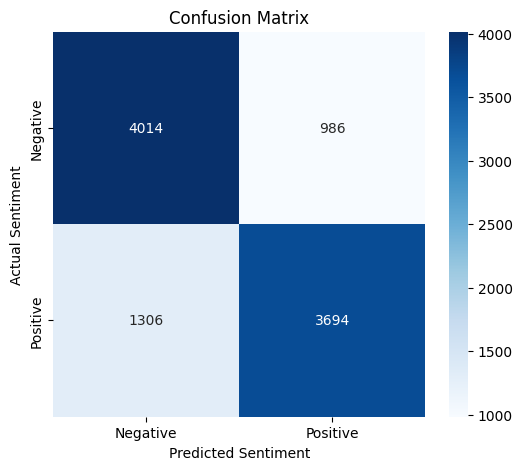

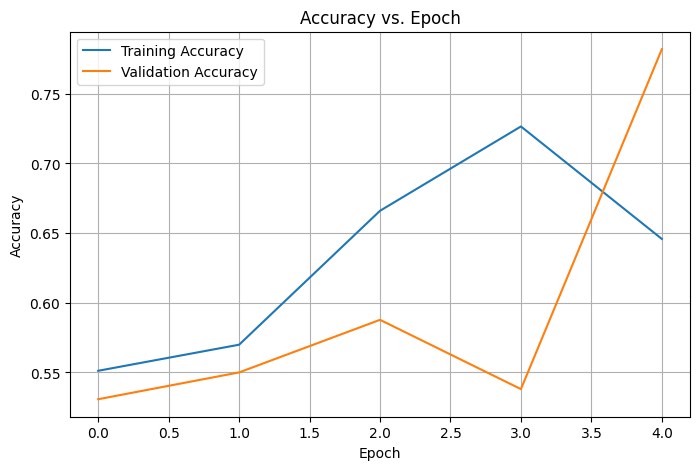

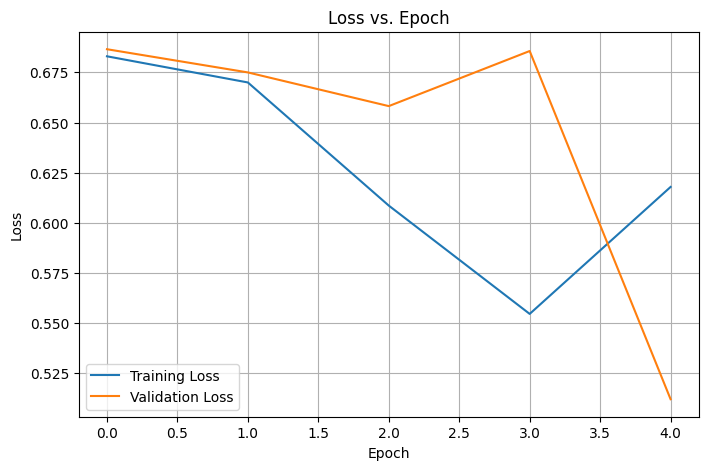

In [3]:
print("24BAD010-Anusri T")
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

print("Training Accuracy:", history.history["accuracy"][-1])
print("Validation Accuracy:", history.history["val_accuracy"][-1])
print("Training Loss:", history.history["loss"][-1])
print("Validation Loss:", history.history["val_loss"][-1])

test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

y_prob = model.predict(X_test, verbose=0)
y_pred = (y_prob >= 0.5).astype(int).flatten()

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Confusion Matrix")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy vs. Epoch")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss vs. Epoch")
plt.legend()
plt.grid(True)
plt.show()


In [4]:
print("24BAD010-Anusri T")
import numpy as np
import pandas as pd
import re
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

VOCAB_SIZE = 10000
MAX_LENGTH = 200

word_index = imdb.get_word_index()

def preprocess_review(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z0-9\s]", "", text)
    words = text.split()
    sequence = [
        word_index.get(word, 0) + 3
        if word_index.get(word, 0) < VOCAB_SIZE
        else 2
        for word in words
    ]
    sequence = [word if word < VOCAB_SIZE else 2 for word in sequence]
    return pad_sequences(
        [sequence],
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post"
    )

reviews = [
    {
        "review": "This movie was absolutely wonderful and amazing. The acting was excellent.",
        "expected": "Positive"
    },
    {
        "review": "I hated this film. The story was boring and the acting was terrible.",
        "expected": "Negative"
    },
    {
        "review": "An excellent movie with a beautiful story and brilliant performances.",
        "expected": "Positive"
    },
    {
        "review": "The worst movie I have ever seen. It was a complete waste of time.",
        "expected": "Negative"
    },
    {
        "review": "The film was enjoyable, entertaining, and full of wonderful moments.",
        "expected": "Positive"
    },
    {
        "review": "The plot was confusing, the characters were dull, and the movie was disappointing.",
        "expected": "Negative"
    }
]

results = []

for item in reviews:
    processed_review = preprocess_review(item["review"])
    probability = float(model.predict(processed_review, verbose=0)[0][0])
    predicted = "Positive" if probability >= 0.5 else "Negative"

    results.append({
        "Review": item["review"],
        "Expected Sentiment": item["expected"],
        "Predicted Sentiment": predicted,
        "Positive Probability": round(probability, 4),
        "Result": "Correct" if predicted == item["expected"] else "Incorrect"
    })

results_df = pd.DataFrame(results)

print("Sentiment Prediction Results")
print(results_df.to_string(index=False))

correct_predictions = sum(
    result["Expected Sentiment"] == result["Predicted Sentiment"]
    for result in results
)

print("\nTotal Reviews:", len(results))
print("Correct Predictions:", correct_predictions)
print("Incorrect Predictions:", len(results) - correct_predictions)
print("Prediction Agreement:", round(correct_predictions / len(results) * 100, 2), "%")

print("\nObservation:")
for result in results:
    print(
        f"Expected: {result['Expected Sentiment']} | "
        f"Predicted: {result['Predicted Sentiment']} | "
        f"Probability: {result['Positive Probability']} | "
        f"{result['Result']}"
    )

results_df.to_csv("sentiment_prediction_results.csv", index=False)
print("\nResults saved to sentiment_prediction_results.csv")


24BAD010-Anusri T
Sentiment Prediction Results
                                                                            Review Expected Sentiment Predicted Sentiment  Positive Probability    Result
        This movie was absolutely wonderful and amazing. The acting was excellent.           Positive            Negative                0.2684 Incorrect
              I hated this film. The story was boring and the acting was terrible.           Negative            Negative                0.2674   Correct
             An excellent movie with a beautiful story and brilliant performances.           Positive            Negative                0.2683 Incorrect
                The worst movie I have ever seen. It was a complete waste of time.           Negative            Negative                0.2675   Correct
              The film was enjoyable, entertaining, and full of wonderful moments.           Positive            Negative                0.2682 Incorrect
The plot was confusing, the c